# CreditParity – Step 6
**Profitable, Fair Lending Decisions**

**Step 6:** Fairness – group metrics, proxies and bias mitigation

**Outcome.** Based on this analysis, CreditParity uses the **CreditParity model** as its final model: a logistic regression without `Sex` and `ForeignWorker` as inputs, trained with **partial reweighing (strength 0.5)**, with `Age` as an input. Model (a) is kept as the comparison model; model (c) and the other reweighing strengths were tested as alternatives (sections 6.4 and 6.5). Step 5 sets the thresholds.

## Step 6 · Fairness

**Question.** Does CreditParity treat applicants differently by **gender** (the `Sex` column), **age** or **foreign worker status**, and can we reduce it?

**Four model variants.** All are logistic regressions with the same preprocessing; only the inputs or the training weights differ.
- **(a) All features** – the model from Steps 4 and 5.
- **(b) Without sensitive features** – `Sex`, `Age` and `ForeignWorker` are removed ("fairness through unawareness").
- **(c) Bias mitigation by reweighing** – all features, but the training applications are reweighted so that, in the weighted training data, default is statistically independent of the combination of age group, sex and foreign worker status (Kamiran & Calders, 2012). The model stays an ordinary logistic regression, so it still gives probabilities and can be explained with SHAP.
- **CreditParity model – final model** – `Sex` and `ForeignWorker` are not model inputs, so two applicants who differ only in gender or foreign worker status get the same score. `Age` stays as an input, as a correction for its proxies. The training weights are **halfway between 1 and the reweighing weights of (c)** (reweighing strength 0.5). Section 6.4 compares strengths from 0 (no reweighing) to 1 (full reweighing) and shows why 0.5 is chosen.

**Decision rule.** Each variant declines an application if its default probability is at or above *its own* cost-optimal threshold (5:1 cost matrix, chosen on out-of-fold predictions as in Step 5). For the zones, this threshold is the lower boundary; the upper boundary follows the precision rule from Step 5: the lowest threshold at which at least 80% of the applications in the red zone are actual defaults.

**Metrics per group.**
- **Rejection rate** – share of applications declined (yellow + red zone, i.e. PD ≥ threshold).
- **Recall** – share of the group's defaults that are caught.
- **False positive rate (FPR)** – share of the group's *good* customers that are declined.
- **Demographic Parity Difference (DPD)** – largest gap in rejection rates between groups. 0 = all groups are declined equally often.
- **Equal Opportunity Difference (EOD)** – largest gap between groups in the FPR, i.e. in the chance that a *creditworthy* applicant is declined. In lending, equal opportunity means that good customers get the same chance of approval regardless of their group. (We also report the recall gap.)

**Data.** Variants are compared on the **out-of-fold predictions of the 4,000 training applications** (larger groups, no test-set use for decisions). The **test set** is used once at the end to confirm the results. Age groups follow Step 2: 19–25, 26–35, 36–50, 51+.

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from fairlearn.metrics import (MetricFrame, selection_rate, false_positive_rate,
                               true_positive_rate, count)
from fairlearn.preprocessing import CorrelationRemover   # pip install fairlearn (also in Colab)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)
ZONE_COLORS = {"Green": "#55A868", "Yellow": "#DDAA33", "Red": "#C44E52"}
VARIANT_COLORS = ["#4C72B0", "#8C8C8C", "#937860", "#55A868"]
STRENGTH_COLORS = ["#4C72B0", "#55A868", "#C44E52", "#8172B3"]

COST_FN, COST_FP = 5, 1
TARGET_PRECISION = 0.80            # precision rule for the red zone (Step 5)
SENSITIVE = ["Sex", "Age", "ForeignWorker"]
AGE_BINS, AGE_LABELS = [18, 25, 35, 50, 100], ["19-25", "26-35", "36-50", "51+"]
REWEIGHING_STRENGTH = 0.5          # CreditParity model (section 6.4)

In [2]:
# Load data
# In the repo the file lives in data/. In Google Colab, upload the CSV via the
# folder icon on the left and set DATA_PATH = "german_credit_data_biased_training.csv"
DATA_PATH = "../data/german_credit_data_biased_training.csv"
df = pd.read_csv(DATA_PATH)
df["y"] = (df["Risk"] == "Risk").astype(int)

X = df.drop(columns=["Risk", "y"])
y = df["y"]
categorical = X.select_dtypes(include=["object", "string"]).columns.tolist()
numeric = X.select_dtypes(include="number").columns.tolist()

# Same stratified 80/20 split as in Steps 3 to 5
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

def age_group(data):
    return pd.cut(data["Age"], AGE_BINS, labels=AGE_LABELS).astype(str)

def groups_of(data):
    """The three sensitive attributes used for the fairness analysis."""
    return {"Sex": data["Sex"], "Age group": age_group(data), "ForeignWorker": data["ForeignWorker"]}

for name, g in groups_of(X_train).items():
    print(name, g.value_counts().sort_index().to_dict())

Sex {'female': 1518, 'male': 2482}
Age group {'19-25': 771, '26-35': 1191, '36-50': 1656, '51+': 382}
ForeignWorker {'no': 100, 'yes': 3900}


### Model variants

Reweighing gives each combination of (group, outcome) the weight *expected share / observed share*. Groups in which defaults are over-represented get lower weights for their defaults and higher weights for their good customers, so the model can no longer learn the group's higher default rate from the data. With a **strength** *s*, each weight becomes (1 − *s*) + *s* × full weight: *s* = 0 is no reweighing, *s* = 1 is full reweighing. The weights are computed on the training part of each fold only.

In [3]:
def make_model(features):
    cat = [c for c in categorical if c in features]
    num = [c for c in numeric if c in features]
    return Pipeline([
        ("prep", ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
            ("num", StandardScaler(), num)])),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])

def reweighing_weights(data, y_true, keys=("Age group", "Sex", "ForeignWorker"), strength=1.0):
    """Kamiran & Calders reweighing: full weight = P(group) * P(y) / P(group, y);
    with strength s the weight is (1 - s) + s * full weight."""
    g = groups_of(data)
    group = pd.Series(["|".join(t) for t in zip(*[g[k].astype(str) for k in keys])],
                      index=data.index)
    w = pd.Series(1.0, index=data.index)
    for gv in group.unique():
        for label in [0, 1]:
            m = (group == gv) & (y_true == label)
            if m.any():
                w[m] = (group == gv).mean() * (y_true == label).mean() / m.mean()
    return ((1 - strength) + strength * w).to_numpy()

ALL_FEATURES = X.columns.tolist()
NON_SENSITIVE = [c for c in ALL_FEATURES if c not in SENSITIVE]
NO_SEX_FW = [c for c in ALL_FEATURES if c not in ["Sex", "ForeignWorker"]]

FINAL = "CreditParity model – final"
VARIANTS = {
    "(a) All features":               {"features": ALL_FEATURES,  "strength": 0.0},
    "(b) Without sensitive features": {"features": NON_SENSITIVE, "strength": 0.0},
    "(c) Reweighing":                 {"features": ALL_FEATURES,  "strength": 1.0},
    FINAL:                            {"features": NO_SEX_FW,     "strength": REWEIGHING_STRENGTH},
}

def fit_variant(spec, data, y_true, keys=("Age group", "Sex", "ForeignWorker")):
    model = make_model(spec["features"])
    if spec["strength"] > 0:
        model.fit(data, y_true, model__sample_weight=reweighing_weights(data, y_true, keys, spec["strength"]))
    else:
        model.fit(data, y_true)
    return model

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def oof_predictions(spec, **kw):
    """Out-of-fold default probabilities on the training set."""
    p = np.zeros(len(y_train))
    for tr, va in cv.split(X_train, y_train):
        m = fit_variant(spec, X_train.iloc[tr], y_train.iloc[tr], **kw)
        p[va] = m.predict_proba(X_train.iloc[va])[:, 1]
    return p

THRESHOLDS = np.round(np.arange(0.01, 1.00, 0.01), 2)

def cost(p, y_true, t):
    return COST_FN * ((p < t) & (y_true == 1)).sum() + COST_FP * ((p >= t) & (y_true == 0)).sum()

def cost_optimal_threshold(p, y_true):
    return float(THRESHOLDS[int(np.argmin([cost(p, y_true, t) for t in THRESHOLDS]))])

y_tr = y_train.to_numpy()
oof, thresholds = {}, {}
for name, spec in VARIANTS.items():
    oof[name] = oof_predictions(spec)
    thresholds[name] = cost_optimal_threshold(oof[name], y_tr)
    print(f"{name:32s} cost-optimal threshold {thresholds[name]:.2f} | "
          f"out-of-fold ROC AUC {roc_auc_score(y_tr, oof[name]):.3f}")

def upper_for_precision(p, y_true, lower, target=TARGET_PRECISION):
    """Lowest threshold >= lower at which the red zone (p >= threshold) has precision >= target."""
    for t in THRESHOLDS[THRESHOLDS >= lower]:
        red = p >= t
        if red.any() and y_true[red].mean() >= target:
            return float(t)
    return 1.0

uppers = {name: upper_for_precision(oof[name], y_tr, thresholds[name]) for name in VARIANTS}
for name in VARIANTS:
    print(f"{name:32s} zones: green < {thresholds[name]:.2f} ≤ yellow < {uppers[name]:.2f} ≤ red")

(a) All features                 cost-optimal threshold 0.11 | out-of-fold ROC AUC 0.856


(b) Without sensitive features   cost-optimal threshold 0.13 | out-of-fold ROC AUC 0.852


(c) Reweighing                   cost-optimal threshold 0.16 | out-of-fold ROC AUC 0.807


CreditParity model – final       cost-optimal threshold 0.13 | out-of-fold ROC AUC 0.838
(a) All features                 zones: green < 0.11 ≤ yellow < 0.58 ≤ red
(b) Without sensitive features   zones: green < 0.13 ≤ yellow < 0.60 ≤ red
(c) Reweighing                   zones: green < 0.16 ≤ yellow < 0.65 ≤ red
CreditParity model – final       zones: green < 0.13 ≤ yellow < 0.62 ≤ red


### 6.1 Group metrics for each variant (out-of-fold, training set)

In [4]:
def group_report(p, y_true, t, data):
    """Per-group metrics and DPD/EOD for one variant."""
    decline = (p >= t).astype(int)
    by_group, summary = {}, {}
    for attr, g in groups_of(data).items():
        mf = MetricFrame(
            metrics={"Applications": count, "Default rate": lambda yt, yp: yt.mean(),
                     "Rejection rate": selection_rate, "Recall": true_positive_rate,
                     "FPR": false_positive_rate},
            y_true=y_true, y_pred=decline, sensitive_features=g.to_numpy())
        by_group[attr] = mf.by_group
        diff = mf.difference()
        summary[attr] = {"DPD": diff["Rejection rate"], "EOD (FPR gap)": diff["FPR"],
                         "Recall gap": diff["Recall"]}
    return by_group, pd.DataFrame(summary).T

reports = {name: group_report(oof[name], y_tr, thresholds[name], X_train) for name in VARIANTS}

for attr in ["Sex", "Age group", "ForeignWorker"]:
    table = pd.concat({name: reports[name][0][attr][["Applications", "Default rate", "Rejection rate",
                                                     "Recall", "FPR"]]
                       for name in VARIANTS}, names=["Variant", attr])
    print(f"\n=== {attr} ===")
    display(table.round(3))


=== Sex ===


Applications  Default rate  \
Variant                        Sex                                  
(a) All features               female        1518.0         0.298   
                               male          2482.0         0.356   
(b) Without sensitive features female        1518.0         0.298   
                               male          2482.0         0.356   
(c) Reweighing                 female        1518.0         0.298   
                               male          2482.0         0.356   
CreditParity model – final     female        1518.0         0.298   
                               male          2482.0         0.356   

                                       Rejection rate  Recall    FPR  
Variant                        Sex                                    
(a) All features               female           0.603   0.960  0.452  
                               male             0.724   0.948  0.601  
(b) Without sensitive features female           0.491   0.914  0.311  
                               male             0.741   0.957  0.622  
(c) Reweighing                 female           0.638   0.918  0.518  
                               male             0.681   0.901  0.560  
CreditParity model – final     female           0.576   0.934  0.423  
                               male             0.776   0.965  0.671


=== Age group ===


Applications  Default rate  \
Variant                        Age group                               
(a) All features               19-25             771.0         0.074   
                               26-35            1191.0         0.207   
                               36-50            1656.0         0.443   
                               51+               382.0         0.783   
(b) Without sensitive features 19-25             771.0         0.074   
                               26-35            1191.0         0.207   
                               36-50            1656.0         0.443   
                               51+               382.0         0.783   
(c) Reweighing                 19-25             771.0         0.074   
                               26-35            1191.0         0.207   
                               36-50            1656.0         0.443   
                               51+               382.0         0.783   
CreditParity model – final     19-25             771.0         0.074   
                               26-35            1191.0         0.207   
                               36-50            1656.0         0.443   
                               51+               382.0         0.783   

                                          Rejection rate  Recall    FPR  
Variant                        Age group                                 
(a) All features               19-25               0.204   0.667  0.167  
                               26-35               0.592   0.894  0.513  
                               36-50               0.890   0.975  0.822  
                               51+                 0.990   0.997  0.964  
(b) Without sensitive features 19-25               0.169   0.649  0.130  
                               26-35               0.537   0.866  0.452  
                               36-50               0.869   0.970  0.789  
                               51+                 0.984   0.993  0.952  
(c) Reweighing                 19-25               0.447   0.947  0.408  
                               26-35               0.624   0.894  0.553  
                               36-50               0.746   0.896  0.627  
                               51+                 0.877   0.936  0.663  
CreditParity model – final     19-25               0.349   0.895  0.305  
                               26-35               0.631   0.915  0.558  
                               36-50               0.849   0.959  0.761  
                               51+                 0.974   0.987  0.928


=== ForeignWorker ===


Applications  Default rate  \
Variant                        ForeignWorker                               
(a) All features               no                    100.0         0.540   
                               yes                  3900.0         0.329   
(b) Without sensitive features no                    100.0         0.540   
                               yes                  3900.0         0.329   
(c) Reweighing                 no                    100.0         0.540   
                               yes                  3900.0         0.329   
CreditParity model – final     no                    100.0         0.540   
                               yes                  3900.0         0.329   

                                              Rejection rate  Recall    FPR  
Variant                        ForeignWorker                                 
(a) All features               no                      0.980   1.000  0.957  
                               yes                     0.671   0.950  0.534  
(b) Without sensitive features no                      0.920   0.963  0.870  
                               yes                     0.639   0.941  0.491  
(c) Reweighing                 no                      0.820   0.870  0.761  
                               yes                     0.661   0.909  0.539  
CreditParity model – final     no                      0.930   0.963  0.891  
                               yes                     0.694   0.954  0.566

In [5]:
# Summary: fairness gaps, cost and ROC AUC per variant
rows = []
for name in VARIANTS:
    s = reports[name][1]
    rows.append({"Variant": name, "Threshold": thresholds[name],
                 "Cost": cost(oof[name], y_tr, thresholds[name]),
                 "ROC AUC": roc_auc_score(y_tr, oof[name]),
                 "Recall": ((oof[name] >= thresholds[name]) & (y_tr == 1)).sum() / y_tr.sum(),
                 **{f"DPD {a}": s.loc[a, "DPD"] for a in s.index},
                 **{f"EOD {a}": s.loc[a, "EOD (FPR gap)"] for a in s.index}})
summary_oof = pd.DataFrame(rows).set_index("Variant")
summary_oof.round(3).T

Variant,(a) All features,(b) Without sensitive features,(c) Reweighing,CreditParity model – final
Threshold,0.110,0.130,0.160,0.130
Cost,1762.000,1711.000,2067.000,1829.000
ROC AUC,0.856,0.852,0.807,0.838
Recall,0.952,0.942,0.907,0.954
DPD Sex,0.121,0.251,0.044,0.200
DPD Age group,0.786,0.816,0.429,0.625
DPD ForeignWorker,0.309,0.281,0.159,0.236
EOD Sex,0.149,0.311,0.041,0.248
EOD Age group,0.797,0.822,0.255,0.622
EOD ForeignWorker,0.423,0.378,0.222,0.325


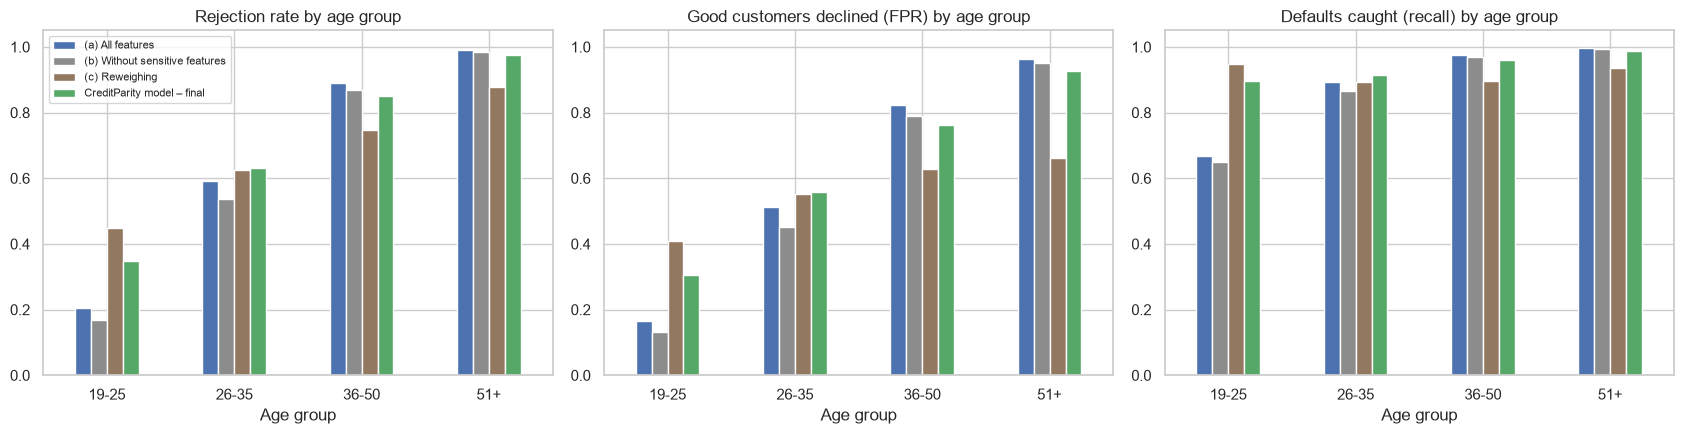

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (metric, title) in zip(axes, [("Rejection rate", "Rejection rate"),
                                      ("FPR", "Good customers declined (FPR)"),
                                      ("Recall", "Defaults caught (recall)")]):
    data = pd.DataFrame({name: reports[name][0]["Age group"][metric] for name in VARIANTS})
    data.plot.bar(ax=ax, color=VARIANT_COLORS, rot=0, legend=(metric == "Rejection rate"))
    ax.set_title(f"{title} by age group")
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Age group")
axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

**Result 6.1 – group metrics (out-of-fold, 4,000 training applications).**

| | (a) All features | (b) Without sensitive features | (c) Reweighing | **CreditParity model – final** |
|---|---|---|---|---|
| Threshold | 0.11 | 0.13 | 0.16 | **0.13** |
| Cost | 1,762 | 1,711 | 2,067 | **1,829** |
| ROC AUC | 0.856 | 0.852 | 0.807 | **0.838** |
| Recall | 0.952 | 0.942 | 0.907 | **0.954** |
| DPD / EOD – Age group | 0.79 / 0.80 | 0.82 / 0.82 | 0.43 / 0.26 | **0.63 / 0.62** |
| DPD / EOD – Gender | 0.12 / 0.15 | 0.25 / 0.31 | 0.04 / 0.04 | **0.20 / 0.25** |
| DPD / EOD – ForeignWorker | 0.31 / 0.42 | 0.28 / 0.38 | 0.16 / 0.22 | **0.24 / 0.33** |

- **Age is by far the largest gap.** With all features, 20% of applicants aged 19–25 are declined, but 99% of those aged 51+. More importantly for fairness, **96% of the *good* customers aged 51+ are declined, compared with 17% of good customers aged 19–25** (EOD 0.80). Part of the rejection gap reflects real differences in the data (default rate 7% vs. 78%), which is why demographic parity alone is not the right target for age. The FPR gap, however, shows that creditworthy older applicants have almost no chance of approval.
- **Gender.** With all features, men are declined more often than women (72% vs. 60%), in line with their higher default rate (36% vs. 30%). Good male customers are also declined more often (FPR 0.60 vs. 0.45).
- **ForeignWorker.** The small group of applicants who are *not* foreign workers (100 in the training set, default rate 54%) is declined in 98% of cases by model (a).
- **(b) Dropping the sensitive features does not reduce the gaps.** The age gap stays the same (EOD 0.82), and the gender gap even doubles (EOD 0.31). Cost and ROC AUC are almost unchanged.
- **(c) Full reweighing cuts the age gap by about two thirds** (EOD 0.80 → 0.26), but the model becomes much weaker (ROC AUC 0.856 → 0.807) and 17% more expensive.
- **The CreditParity model uses partial reweighing** (section 6.4). It reduces the age gap less (EOD 0.62), but keeps most of the predictive power (ROC AUC 0.838) and costs only 4% more than model (a).
- **Leveling down.** Reweighing narrows the age gap from both sides: good customers aged 19–25 are declined *more* often (0.17 → 0.31 with the CreditParity model), while for good customers aged 51+ the main change is *how* they are declined: far fewer automatic declines, more manual reviews (section 6.3). A fairer model is not automatically better for every group.

### 6.2 Why dropping sensitive features is not enough: proxies

If the remaining 17 features can predict a sensitive attribute, the model can still treat the groups differently without ever seeing the attribute. We test this by predicting each sensitive attribute from the non-sensitive features only (5-fold CV, logistic regression). A ROC AUC of 0.5 means "no information", 1.0 means "perfect proxy".

In [7]:
proxy_targets = {
    "Age 51+": (X_train["Age"] > 50).astype(int),
    "Age 36+": (X_train["Age"] > 35).astype(int),
    "Female": (X_train["Sex"] == "female").astype(int),
    "Not a foreign worker": (X_train["ForeignWorker"] == "no").astype(int),
}
proxy_rows = []
for target, t_y in proxy_targets.items():
    auc = cross_val_score(make_model(NON_SENSITIVE), X_train[NON_SENSITIVE], t_y,
                          cv=cv, scoring="roc_auc")
    proxy_rows.append({"Sensitive attribute": target, "ROC AUC from other features": auc.mean(),
                       "Std": auc.std()})
pd.DataFrame(proxy_rows).set_index("Sensitive attribute").round(3)

,ROC AUC from other features,Std
Sensitive attribute,,
Age 51+,0.904,0.012
Age 36+,0.883,0.008
Female,0.692,0.017
Not a foreign worker,0.646,0.015


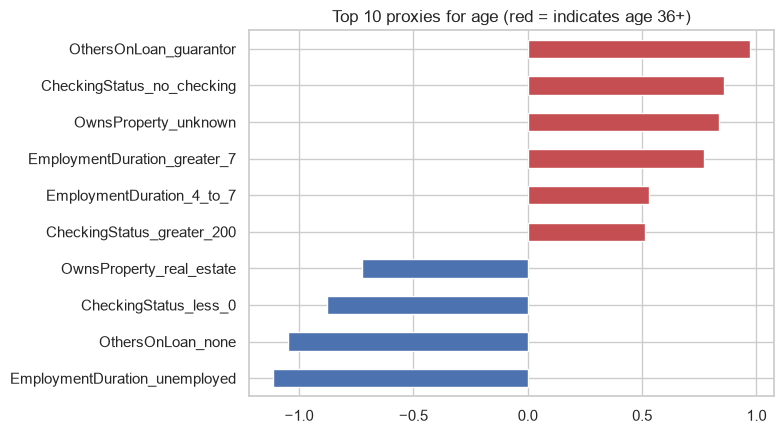

In [8]:
# Which features carry the age information? Strongest predictors of "Age 36+"
proxy_model = make_model(NON_SENSITIVE).fit(X_train[NON_SENSITIVE], proxy_targets["Age 36+"])
names = [n.split("__", 1)[1] for n in proxy_model.named_steps["prep"].get_feature_names_out()]
coef = pd.Series(proxy_model.named_steps["model"].coef_[0], index=names)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)
top.sort_values().plot.barh(figsize=(8, 4.5),
    color=["#C44E52" if v > 0 else "#4C72B0" for v in top.sort_values()])
plt.title("Top 10 proxies for age (red = indicates age 36+)")
plt.tight_layout()
plt.show()

In [9]:
# Does mitigation work without the sensitive attributes? And how does another method compare?
extra = {
    "(c) Reweighing (all features)": oof["(c) Reweighing"],
    "Reweighing without sensitive features": oof_predictions(
        {"features": NON_SENSITIVE, "strength": 1.0}),
}

def correlation_remover_oof(alpha):
    """fairlearn CorrelationRemover: removes the linear correlation of all features with
    Age, Sex and ForeignWorker (alpha = 1: fully, alpha = 0.5: halfway)."""
    p = np.zeros(len(y_train))
    for tr, va in cv.split(X_train, y_train):
        prep = ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
            ("num", StandardScaler(), numeric)])
        prep.fit(X_train.iloc[tr])
        ids = [i for i, n in enumerate(prep.get_feature_names_out())
               if n == "num__Age" or n.startswith(("cat__Sex_", "cat__ForeignWorker_"))]
        m = Pipeline([("prep", prep),
                      ("cr", CorrelationRemover(sensitive_feature_ids=ids, alpha=alpha)),
                      ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
        m.fit(X_train.iloc[tr], y_train.iloc[tr])
        p[va] = m.predict_proba(X_train.iloc[va])[:, 1]
    return p

for alpha in [0.5, 1.0]:
    extra[f"CorrelationRemover (alpha = {alpha})"] = correlation_remover_oof(alpha)

rows = []
for name, p in {"(a) All features": oof["(a) All features"], **extra}.items():
    t = cost_optimal_threshold(p, y_tr)
    by_group, s = group_report(p, y_tr, t, X_train)
    fpr_age = by_group["Age group"]["FPR"]
    rows.append({"Method": name, "Threshold": t, "Cost": cost(p, y_tr, t),
                 "ROC AUC": roc_auc_score(y_tr, p),
                 "FPR 19-25": fpr_age["19-25"], "FPR 51+": fpr_age["51+"],
                 "EOD Age group": s.loc["Age group", "EOD (FPR gap)"],
                 "EOD Sex": s.loc["Sex", "EOD (FPR gap)"]})
pd.DataFrame(rows).set_index("Method").round(3)

,Threshold,Cost,ROC AUC,FPR 19-25,FPR 51+,EOD Age group,EOD Sex
Method,,,,,,,
(a) All features,0.11,1762,0.856,0.167,0.964,0.797,0.149
(c) Reweighing (all features),0.16,2067,0.807,0.408,0.663,0.255,0.041
Reweighing without sensitive features,0.17,1911,0.831,0.254,0.964,0.710,0.225
CorrelationRemover (alpha = 0.5),0.13,1838,0.836,0.328,0.831,0.504,0.191
CorrelationRemover (alpha = 1.0),0.11,2565,0.730,0.978,0.711,0.267,0.032


**Result 6.2 – proxies.**
- **Age can be reconstructed from the other features.** Without seeing `Age`, a logistic regression identifies applicants aged 51+ with a ROC AUC of **0.90** (36+: 0.88). The strongest proxies are a guarantor on the loan (`OthersOnLoan`), the checking account status, unknown property and employment duration over 7 years. Gender (0.69) and foreign worker status (0.65) are weaker, but still not hidden.
- **Mitigation needs the sensitive attribute.** Reweighing *without* the sensitive features hardly helps (age EOD 0.71; 96% of good customers aged 51+ are still declined). The model can only offset the proxies if it knows the attribute it should be fair about. This is the opposite of "fairness through unawareness".
- **Another method for comparison.** fairlearn's `CorrelationRemover` removes the correlation between the features and the sensitive attributes. Halfway (alpha = 0.5) it reduces the age EOD to 0.50 at a cost of 1,838. Fully applied (alpha = 1) it overcorrects: ROC AUC falls to 0.73 and 98% of good customers aged 19–25 are declined. We also tried fairlearn's `ExponentiatedGradient`, but it optimizes accuracy rather than our 5:1 cost matrix and produced unusable probabilities on this data, so it is not shown.

**Why the CreditParity model can correct for age.** It keeps `Age` as an input, so reweighing can offset part of the age proxies. It drops only `Sex` and `ForeignWorker`, which the other features reflect only weakly (ROC AUC 0.69 and 0.65).

**Answer to the key question.** Simply dropping sensitive features is **not enough**. The age information is still in the data through proxies, and the age gap stays at the same level.

### 6.3 Fairness per zone

Which groups are approved automatically, sent to an analyst, or declined with an explanation? We show the zone shares per group for each variant (lower boundary = the variant's own cost-optimal threshold, upper boundary = the variant's own 80%-precision boundary).

In [10]:
def zone_of(p, lower, upper):
    return np.where(p < lower, "Green", np.where(p >= upper, "Red", "Yellow"))

zone_rows = []
for name in VARIANTS:
    zone = pd.Series(zone_of(oof[name], thresholds[name], uppers[name]), index=X_train.index)
    for attr, g in groups_of(X_train).items():
        shares = pd.crosstab(g, zone, normalize="index").reindex(columns=["Green", "Yellow", "Red"],
                                                                 fill_value=0)
        for grp, r in shares.iterrows():
            zone_rows.append({"Variant": name, "Attribute": attr, "Group": grp, **r.to_dict()})
zone_shares = pd.DataFrame(zone_rows).set_index(["Variant", "Attribute", "Group"])
zone_shares.round(3)

Green  Yellow    Red
Variant                        Attribute     Group                       
(a) All features               Sex           female  0.397   0.384  0.219
                                             male    0.276   0.481  0.243
                               Age group     19-25   0.796   0.198  0.005
                                             26-35   0.408   0.534  0.058
                                             36-50   0.110   0.553  0.337
                                             51+     0.010   0.191  0.798
                               ForeignWorker no      0.020   0.560  0.420
                                             yes     0.329   0.442  0.229
(b) Without sensitive features Sex           female  0.509   0.338  0.153
                                             male    0.259   0.487  0.255
                               Age group     19-25   0.831   0.165  0.004
                                             26-35   0.463   0.478  0.060
                                             36-50   0.131   0.566  0.303
                                             51+     0.016   0.228  0.757
                               ForeignWorker no      0.080   0.610  0.310
                                             yes     0.361   0.426  0.214
(c) Reweighing                 Sex           female  0.362   0.509  0.128
                                             male    0.319   0.517  0.164
                               Age group     19-25   0.553   0.402  0.045
                                             26-35   0.376   0.535  0.089
                                             36-50   0.254   0.546  0.200
                                             51+     0.123   0.534  0.343
                               ForeignWorker no      0.180   0.620  0.200
                                             yes     0.339   0.511  0.149
CreditParity model – final     Sex           female  0.424   0.467  0.109
                                             male    0.224   0.546  0.230
                               Age group     19-25   0.651   0.328  0.021
                                             26-35   0.369   0.547  0.084
                                             36-50   0.151   0.605  0.244
                                             51+     0.026   0.408  0.565
                               ForeignWorker no      0.070   0.700  0.230
                                             yes     0.306   0.511  0.183

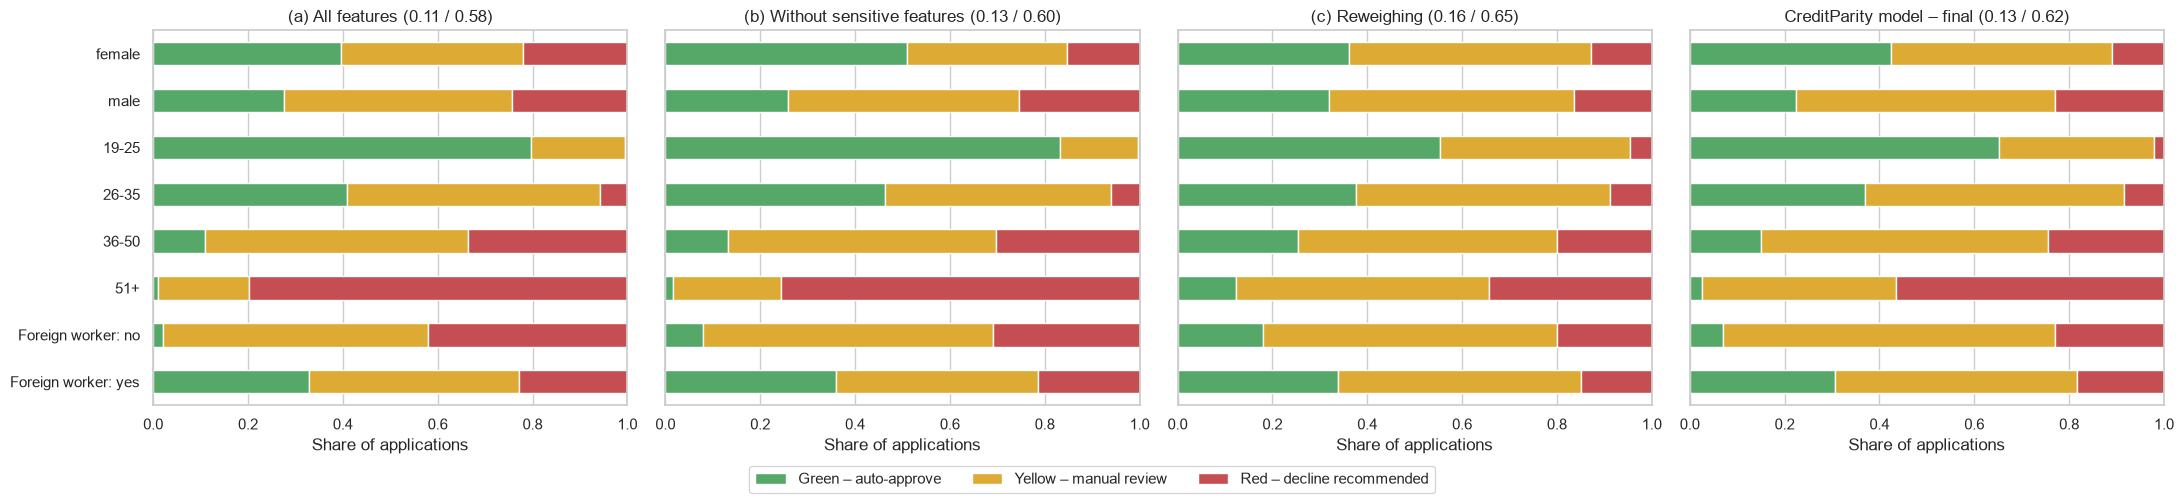

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4.8), sharey=True)
for ax, name in zip(axes, VARIANTS):
    zs = zone_shares.loc[name]
    zs.index = [f"Foreign worker: {g}" if a == "ForeignWorker" else g for a, g in zs.index]
    zs.plot.barh(stacked=True, ax=ax, color=[ZONE_COLORS[z] for z in zs.columns], legend=False)
    ax.set_title(f"{name} ({thresholds[name]:.2f} / {uppers[name]:.2f})")
    ax.set_xlim(0, 1)
    ax.set_xlabel("Share of applications")
    ax.invert_yaxis()
fig.legend(["Green – auto-approve", "Yellow – manual review", "Red – decline recommended"],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.show()

In [12]:
# Where do the GOOD customers of each age group end up? (counts, out-of-fold)
def good_customer_zones(p_dict, y_true, data, lowers, upper_dict):
    ag = age_group(data).to_numpy()
    rows = []
    for name in p_dict:
        zone = zone_of(p_dict[name], lowers[name], upper_dict[name])
        for grp in AGE_LABELS:
            m = (ag == grp) & (y_true == 0)
            rows.append({"Variant": name, "Age group": grp, "Good customers": int(m.sum()),
                         "Green": int((m & (zone == "Green")).sum()),
                         "Yellow": int((m & (zone == "Yellow")).sum()),
                         "Red": int((m & (zone == "Red")).sum()),
                         "PD ≥ lower boundary (yellow + red)": (m & (zone != "Green")).sum() / m.sum(),
                         "Auto-declined (red)": (m & (zone == "Red")).sum() / m.sum()})
    return pd.DataFrame(rows).set_index(["Variant", "Age group"])

good_zones_oof = good_customer_zones(oof, y_tr, X_train, thresholds, uppers)
good_zones_oof.round(3)

Good customers  Green  Yellow  Red  \
Variant                        Age group                                       
(a) All features               19-25                 714    595     117    2   
                               26-35                 945    460     461   24   
                               36-50                 922    164     640  118   
                               51+                    83      3      39   41   
(b) Without sensitive features 19-25                 714    621      92    1   
                               26-35                 945    518     402   25   
                               36-50                 922    195     622  105   
                               51+                    83      4      42   37   
(c) Reweighing                 19-25                 714    423     268   23   
                               26-35                 945    422     470   53   
                               36-50                 922    344     539   39   
                               51+                    83     28      50    5   
CreditParity model – final     19-25                 714    496     208   10   
                               26-35                 945    418     478   49   
                               36-50                 922    220     632   70   
                               51+                    83      6      61   16   

                                          PD ≥ lower boundary (yellow + red)  \
Variant                        Age group                                       
(a) All features               19-25                                   0.167   
                               26-35                                   0.513   
                               36-50                                   0.822   
                               51+                                     0.964   
(b) Without sensitive features 19-25                                   0.130   
                               26-35                                   0.452   
                               36-50                                   0.789   
                               51+                                     0.952   
(c) Reweighing                 19-25                                   0.408   
                               26-35                                   0.553   
                               36-50                                   0.627   
                               51+                                     0.663   
CreditParity model – final     19-25                                   0.305   
                               26-35                                   0.558   
                               36-50                                   0.761   
                               51+                                     0.928   

                                          Auto-declined (red)  
Variant                        Age group                       
(a) All features               19-25                    0.003  
                               26-35                    0.025  
                               36-50                    0.128  
                               51+                      0.494  
(b) Without sensitive features 19-25                    0.001  
                               26-35                    0.026  
                               36-50                    0.114  
                               51+                      0.446  
(c) Reweighing                 19-25                    0.032  
                               26-35                    0.056  
                               36-50                    0.042  
                               51+                      0.060  
CreditParity model – final     19-25                    0.014  
                               26-35                    0.052  
                               36-50                    0.076  
                               51+                      0.193

**Result 6.3 – fairness per zone (out-of-fold).** Each variant uses its own boundaries: (a) 0.11 / 0.58, (b) 0.13 / 0.60, (c) 0.16 / 0.65, CreditParity model 0.13 / 0.62.

| Zone shares 🟢 / 🟡 / 🔴 | (a) All features | CreditParity model |
|---|---|---|
| Age 19–25 | 79.6% / 19.8% / 0.5% | 65.1% / 32.8% / 2.1% |
| Age 26–35 | 40.8% / 53.4% / 5.8% | 36.9% / 54.7% / 8.4% |
| Age 36–50 | 11.0% / 55.3% / 33.7% | 15.1% / 60.5% / 24.4% |
| Age 51+ | 1.0% / 19.1% / **79.8%** | 2.6% / 40.8% / **56.5%** |
| Female | 39.7% / 38.4% / 21.9% | 42.4% / 46.7% / 10.9% |
| Male | 27.6% / 48.1% / 24.3% | 22.4% / 54.6% / 23.0% |
| Foreign worker: no / yes (red) | 42.0% / 22.9% | 23.0% / 18.3% |

**Good customers aged 51+ (83 in the training set):**

| | 🟢 Green | 🟡 Yellow | 🔴 Red (automatic decline) |
|---|---|---|---|
| (a) All features | 3 | 39 | **41 (49%)** |
| (b) Without sensitive features | 4 | 42 | 37 (45%) |
| (c) Reweighing | 28 | 50 | 5 (6%) |
| **CreditParity model** | 6 | 61 | **16 (19%)** |

- **With model (a), half of the creditworthy applicants aged 51+ are declined automatically**, and 80% of all applicants aged 51+ land in the red zone.
- **With the CreditParity model, automatic declines of creditworthy applicants aged 51+ fall by more than half** (16 of 83 vs. 41 with model (a)). Most go to manual review (61), so a person looks at their case. Few are approved directly (6): the correction mainly turns automatic declines into human decisions.
- **Young applicants.** With the CreditParity model, 30.5% of good customers aged 19–25 are not auto-approved (vs. 17% with (a)), but only 10 of 714 (1.4%) are declined automatically; the rest go to an analyst.
- **Gender.** With the CreditParity model, men are auto-approved less often (22% vs. 42%) and land in the red zone more often (23% vs. 11%) than women. Section 6.5 shows why.
- **Implication.** The bank should monitor zone shares by group, not only overall rejection rates. The dashboard (Step 9) shows these shares.

### 6.4 Reweighing strength

Full reweighing reduces the age gap the most, but in this dataset it rates young applicants as much riskier than their actual default rate. We therefore compare five strengths (0 = no reweighing, 1 = full reweighing), with the inputs of the CreditParity model and the same threshold rules as in Step 5, and look for a balance between cost, the age gap and the burden on young applicants.

In [13]:
STRENGTHS = [0.0, 0.25, 0.5, 0.75, 1.0]

def strength_spec(s):
    return {"features": NO_SEX_FW, "strength": s}

def age_coefficient(model):
    """Age coefficient in log-odds per year (the model standardizes Age)."""
    prep = model.named_steps["prep"]
    scaler = prep.named_transformers_["num"]
    coef = pd.Series(model.named_steps["model"].coef_[0], index=prep.get_feature_names_out())["num__Age"]
    return coef / scaler.scale_[list(scaler.feature_names_in_).index("Age")]

def strength_summary(p, y_true, data, lower, upper):
    """Cost, fairness and the burden on young and older applicants for one strength."""
    by_group, s = group_report(p, y_true, lower, data)
    zone = zone_of(p, lower, upper)
    ag = age_group(data).to_numpy()
    good = y_true == 0
    g25, g51 = good & (ag == "19-25"), good & (ag == "51+")
    return {"Boundaries": f"{lower:.2f} / {upper:.2f}", "Cost": int(cost(p, y_true, lower)),
            "ROC AUC": round(roc_auc_score(y_true, p), 3),
            "Recall": round(((p >= lower) & (y_true == 1)).sum() / y_true.sum(), 3),
            "EOD Age group": round(s.loc["Age group", "EOD (FPR gap)"], 3),
            "EOD Gender": round(s.loc["Sex", "EOD (FPR gap)"], 3),
            "Good 51+ auto-declined": f"{int((g51 & (zone == 'Red')).sum())} of {int(g51.sum())}",
            "Good 19-25 not auto-approved": f"{(zone[g25] != 'Green').mean():.1%}",
            "Good 19-25 auto-declined": f"{(zone[g25] == 'Red').mean():.1%}",
            "19-25 mean PD vs. default rate": f"{p[ag == '19-25'].mean():.1%} vs. {y_true[ag == '19-25'].mean():.1%}",
            "51+ mean PD vs. default rate": f"{p[ag == '51+'].mean():.1%} vs. {y_true[ag == '51+'].mean():.1%}",
            "Zones G / Y / R": " / ".join(f"{(zone == z).mean():.1%}" for z in ["Green", "Yellow", "Red"]),
            "Good customers auto-declined": int(((zone == "Red") & good).sum()),
            "Defaults auto-approved": int(((zone == "Green") & (y_true == 1)).sum())}

strength_oof, strength_lower, strength_upper, strength_models = {}, {}, {}, {}
for s in STRENGTHS:
    strength_oof[s] = oof_predictions(strength_spec(s))
    strength_lower[s] = cost_optimal_threshold(strength_oof[s], y_tr)
    strength_upper[s] = upper_for_precision(strength_oof[s], y_tr, strength_lower[s])
    strength_models[s] = fit_variant(strength_spec(s), X_train, y_train)   # for the age coefficient

strength_table_oof = pd.DataFrame({
    f"s = {s}": {**strength_summary(strength_oof[s], y_tr, X_train, strength_lower[s], strength_upper[s]),
                 "Age coefficient (log-odds per year)": round(age_coefficient(strength_models[s]), 4),
                 "Odds factor, 10 years younger": round(float(np.exp(-10 * age_coefficient(strength_models[s]))), 2)}
    for s in STRENGTHS})
print("Out-of-fold (4,000 training applications); s = 0.5 is the CreditParity model")
strength_table_oof

Out-of-fold (4,000 training applications); s = 0.5 is the CreditParity model


,s = 0.0,s = 0.25,s = 0.5,s = 0.75,s = 1.0
Boundaries,0.11 / 0.61,0.12 / 0.60,0.13 / 0.62,0.13 / 0.65,0.15 / 0.71
Cost,1704,1761,1829,1932,2093
ROC AUC,0.853,0.848,0.838,0.822,0.8
Recall,0.957,0.96,0.954,0.951,0.917
EOD Age group,0.844,0.71,0.622,0.482,0.286
EOD Gender,0.285,0.255,0.248,0.21,0.209
Good 51+ auto-declined,40 of 83,27 of 83,16 of 83,6 of 83,1 of 83
Good 19-25 not auto-approved,14.4%,24.2%,30.5%,38.5%,42.4%
Good 19-25 auto-declined,0.1%,0.6%,1.4%,2.5%,2.5%
19-25 mean PD vs. default rate,7.1% vs. 7.4%,10.6% vs. 7.4%,14.1% vs. 7.4%,17.6% vs. 7.4%,21.2% vs. 7.4%


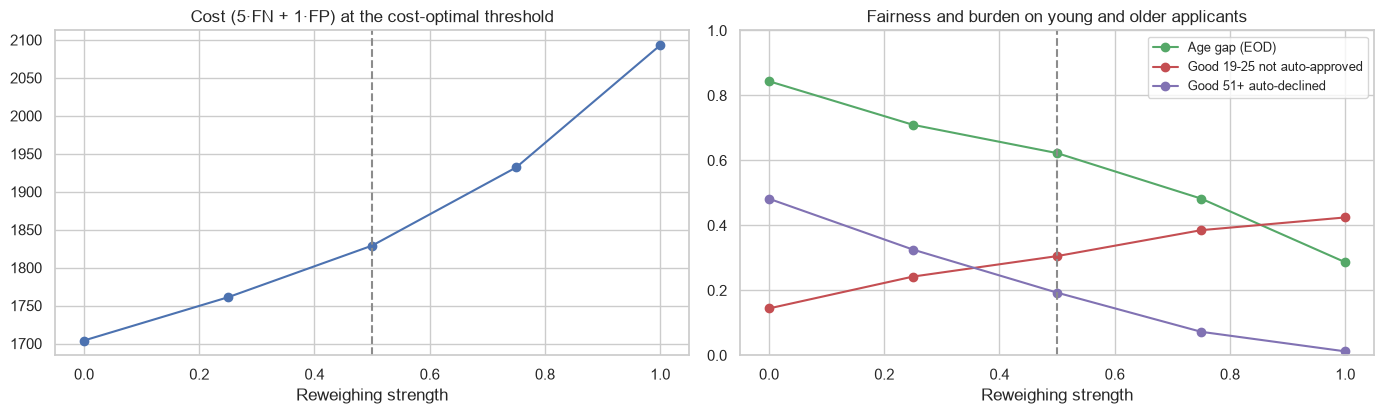

In [14]:
# The trade-off over the strength (out-of-fold)
ag_tr = age_group(X_train).to_numpy()
g25_tr, g51_tr = (y_tr == 0) & (ag_tr == "19-25"), (y_tr == 0) & (ag_tr == "51+")
curve = pd.DataFrame([{
    "Strength": s,
    "Cost": cost(strength_oof[s], y_tr, strength_lower[s]),
    "Age gap (EOD)": group_report(strength_oof[s], y_tr, strength_lower[s], X_train)[1].loc["Age group", "EOD (FPR gap)"],
    "Good 19-25 not auto-approved": (strength_oof[s][g25_tr] >= strength_lower[s]).mean(),
    "Good 51+ auto-declined": (strength_oof[s][g51_tr] >= strength_upper[s]).mean(),
} for s in STRENGTHS]).set_index("Strength")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
axes[0].plot(curve.index, curve["Cost"], marker="o", color="#4C72B0")
axes[0].set_title("Cost (5·FN + 1·FP) at the cost-optimal threshold")
axes[0].set_xlabel("Reweighing strength")
for col, color in zip(["Age gap (EOD)", "Good 19-25 not auto-approved", "Good 51+ auto-declined"],
                      STRENGTH_COLORS[1:]):
    axes[1].plot(curve.index, curve[col], marker="o", color=color, label=col)
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("Reweighing strength")
axes[1].set_title("Fairness and burden on young and older applicants")
axes[1].legend(fontsize=9)
for ax in axes:
    ax.axvline(REWEIGHING_STRENGTH, ls="--", color="#8C8C8C")
plt.tight_layout()
plt.show()

**Result 6.4 – reweighing strength (out-of-fold, 4,000 training applications).**

| Strength | 0 (none) | 0.25 | **0.5 – CreditParity** | 0.75 | 1 (full) |
|---|---|---|---|---|---|
| Boundaries | 0.11 / 0.61 | 0.12 / 0.60 | **0.13 / 0.62** | 0.13 / 0.65 | 0.15 / 0.71 |
| Cost | 1,704 | 1,761 | **1,829** | 1,932 | 2,093 |
| ROC AUC | 0.853 | 0.848 | **0.838** | 0.822 | 0.800 |
| Age gap (EOD) | 0.84 | 0.71 | **0.62** | 0.48 | 0.29 |
| Gender gap (EOD) | 0.29 | 0.26 | **0.25** | 0.21 | 0.21 |
| Good customers 51+ declined automatically | 40 of 83 | 27 of 83 | **16 of 83** | 6 of 83 | 1 of 83 |
| Good customers 19–25 not auto-approved | 14.4% | 24.2% | **30.5%** | 38.5% | 42.4% |
| Good customers 19–25 declined automatically | 0.1% | 0.6% | **1.4%** | 2.5% | 2.5% |
| Age 19–25: mean PD vs. default rate | 7.1% vs. 7.4% | 10.6% vs. 7.4% | **14.1% vs. 7.4%** | 17.6% vs. 7.4% | 21.2% vs. 7.4% |
| Age 51+: mean PD vs. default rate | 75.9% vs. 78.3% | 69.0% vs. 78.3% | **62.5% vs. 78.3%** | 56.1% vs. 78.3% | 49.4% vs. 78.3% |
| Age coefficient (log-odds per year) | +0.009 | −0.023 | **−0.049** | −0.072 | −0.094 |
| Odds factor, 10 years younger | 0.92 | 1.25 | **1.62** | 2.05 | 2.55 |
| Manual review | 46.3% | 48.9% | **51.6%** | 56.4% | 58.1% |

**Why 0.5.** Stronger reweighing reduces the age gap and the automatic declines of good older customers, but raises the cost and the share of good young customers who are not auto-approved. Strength 0.5 balances these goals: compared with full reweighing, it lowers the cost by 13% and roughly halves the age penalty for young applicants (odds factor 1.62 instead of 2.55 per ten years); compared with no reweighing, it reduces the age gap (0.62 vs. 0.84) and the automatic declines of good customers aged 51+ (16 vs. 40 of 83). The CreditParity model therefore uses strength **0.5**; the test set confirms the pattern (section 6.6).

### 6.5 Gender: equal treatment vs. equal outcomes

Model (c) has the smallest gender gap, but it uses `Sex` as an input. Its coefficients show that, *holding all other features equal*, it rates women as riskier than men (Step 7). That is direct gender-based treatment, which CreditParity rules out. The CreditParity model removes `Sex` as an input. To check whether the result depends on the exact way gender is removed, we compare two approaches with the same (full) reweighing as (c):

- **Full reweighing without `Sex`/`ForeignWorker`** – strength 1 from section 6.4.
- **(e) Model (c) with a neutral gender effect** – trained exactly like (c), but at prediction time every applicant gets the same, average contribution for `Sex` and `ForeignWorker`. Men and women with the same other features therefore get the same score.

If both show the same gender gap, the gap is not caused by how we remove gender, but by the data itself.

In [15]:
def fit_neutral(data, y_true):
    """Variant (e): model (c) whose Sex and ForeignWorker columns are set to their
    training average at prediction time."""
    m = fit_variant(VARIANTS["(c) Reweighing"], data, y_true)
    Z = m.named_steps["prep"].transform(data)
    m.neutral_values_ = np.asarray(Z.mean(axis=0)).ravel()
    return m

def predict_neutral(m, data):
    Z = m.named_steps["prep"].transform(data)
    Z = Z.toarray() if hasattr(Z, "toarray") else np.array(Z, dtype=float)
    cols = [i for i, n in enumerate(m.named_steps["prep"].get_feature_names_out())
            if n.startswith(("cat__Sex_", "cat__ForeignWorker_"))]
    Z[:, cols] = m.neutral_values_[cols]
    return m.named_steps["model"].predict_proba(Z)[:, 1]

p_e = np.zeros(len(y_tr))
for tr, va in cv.split(X_train, y_train):
    p_e[va] = predict_neutral(fit_neutral(X_train.iloc[tr], y_train.iloc[tr]), X_train.iloc[va])
t_e = cost_optimal_threshold(p_e, y_tr)
u_e = upper_for_precision(p_e, y_tr, t_e)

def sex_summary(p, y_true, data, lower, upper):
    by_group, s = group_report(p, y_true, lower, data)
    zone = pd.Series(zone_of(p, lower, upper), index=data.index)
    shares = pd.crosstab(data["Sex"], zone, normalize="index").reindex(columns=["Green", "Yellow", "Red"], fill_value=0)
    fpr = by_group["Sex"]["FPR"]
    return {"Boundaries": f"{lower:.2f} / {upper:.2f}", "Cost": cost(p, y_true, lower),
            "ROC AUC": round(roc_auc_score(y_true, p), 3),
            "EOD Sex": round(s.loc["Sex", "EOD (FPR gap)"], 3),
            "FPR female / male": f"{fpr['female']:.2f} / {fpr['male']:.2f}",
            "Zones female (G/Y/R)": " / ".join(f"{v:.0%}" for v in shares.loc["female"]),
            "Zones male (G/Y/R)": " / ".join(f"{v:.0%}" for v in shares.loc["male"]),
            "EOD Age group": round(s.loc["Age group", "EOD (FPR gap)"], 3)}

sex_rows = {name: sex_summary(oof[name], y_tr, X_train, thresholds[name], uppers[name])
            for name in ["(a) All features", "(c) Reweighing"]}
sex_rows["Full reweighing, no Sex/FW (s = 1)"] = sex_summary(strength_oof[1.0], y_tr, X_train,
                                                              strength_lower[1.0], strength_upper[1.0])
sex_rows["(e) Model (c), neutral gender effect"] = sex_summary(p_e, y_tr, X_train, t_e, u_e)
sex_rows[FINAL] = sex_summary(oof[FINAL], y_tr, X_train, thresholds[FINAL], uppers[FINAL])
print("Out-of-fold (training set)")
pd.DataFrame(sex_rows).T

Out-of-fold (training set)


,Boundaries,Cost,ROC AUC,EOD Sex,FPR female / male,Zones female (G/Y/R),Zones male (G/Y/R),EOD Age group
(a) All features,0.11 / 0.58,1762,0.856,0.149,0.45 / 0.60,40% / 38% / 22%,28% / 48% / 24%,0.797
(c) Reweighing,0.16 / 0.65,2067,0.807,0.041,0.52 / 0.56,36% / 51% / 13%,32% / 52% / 16%,0.255
"Full reweighing, no Sex/FW (s = 1)",0.15 / 0.71,2093,0.8,0.209,0.45 / 0.66,42% / 52% / 6%,24% / 62% / 14%,0.286
"(e) Model (c), neutral gender effect",0.11 / 0.71,2050,0.806,0.206,0.52 / 0.72,36% / 57% / 6%,19% / 65% / 16%,0.332
CreditParity model – final,0.13 / 0.62,1829,0.838,0.248,0.42 / 0.67,42% / 47% / 11%,22% / 55% / 23%,0.622


In [16]:
# Sex coefficients: only (a) and (c) use Sex as an input
coef_sex = {}
for name in ["(a) All features", "(c) Reweighing"]:
    m = fit_variant(VARIANTS[name], X_train, y_train)
    c = pd.Series(m.named_steps["model"].coef_[0], index=m.named_steps["prep"].get_feature_names_out())
    coef_sex[name] = {"Sex_female": c["cat__Sex_female"], "Sex_male": c["cat__Sex_male"],
                      "female − male (log-odds)": c["cat__Sex_female"] - c["cat__Sex_male"]}
pd.DataFrame(coef_sex).round(3)

,(a) All features,(c) Reweighing
Sex_female,0.213,0.210
Sex_male,-0.488,-0.503
female − male (log-odds),0.701,0.713


**Result 6.5 – equal treatment vs. equal outcomes for gender.**

| Out-of-fold | (a) All features | (c) Reweighing | Full reweighing, no Sex/FW | (e) (c) with neutral gender effect | **CreditParity model** |
|---|---|---|---|---|---|
| Uses gender for the score | yes | yes | no | no | **no** |
| Cost | 1,762 | 2,067 | 2,093 | 2,050 | **1,829** |
| ROC AUC | 0.856 | 0.807 | 0.800 | 0.806 | **0.838** |
| EOD Gender | 0.15 | **0.04** | 0.21 | 0.21 | 0.25 |
| Good customers declined, female / male | 0.45 / 0.60 | 0.52 / 0.56 | 0.45 / 0.66 | 0.52 / 0.72 | 0.42 / 0.67 |
| EOD Age group | 0.80 | 0.26 | 0.29 | 0.33 | 0.62 |

- **Model (c) achieves equal outcomes through unequal treatment.** Its gender coefficients are female +0.21 and male −0.50: with all other features equal, a woman's log-odds of default are 0.71 higher than a man's. The small gender gap of (c) exists only because this offsets the less favorable other features of men in this dataset.
- **Every model that treats genders equally shows a similar gap.** With the same full reweighing as (c), removing `Sex` as an input and neutralizing the gender effect at prediction time (e) both end up at an EOD of about **0.21**, against men. The gap therefore does not depend on how gender is removed. It comes from differences in the other features between men and women. The CreditParity model, with its partial reweighing, shows a gap of 0.25.
- **The trade-off.** On this data, CreditParity can have *equal treatment* (same score for the same features, regardless of gender) or *equal outcomes* (same decline rates for good men and women), but not both. **CreditParity chooses equal treatment**: no applicant's score depends directly on gender. The remaining outcome gap is documented, needs legal review (indirect discrimination) and should be monitored.
- **Age is treated differently on purpose.** The CreditParity model uses `Age` directly, as a partial correction for its strong proxies. Without it, the age gap returns (6.2). This also needs legal review.

### 6.6 Confirmation on the test set

The variants and the five reweighing strengths are trained on all 4,000 training applications and applied with their thresholds to the 1,000 test applications. Group sizes are smaller here (only 23 test applicants are not foreign workers), so the test numbers are less precise.

In [17]:
y_te = y_test.to_numpy()
test_rows, test_reports = [], {}
for name, spec in VARIANTS.items():
    model = fit_variant(spec, X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    t = thresholds[name]
    by_group, s = group_report(p, y_te, t, X_test)
    test_reports[name] = by_group
    test_rows.append({"Variant": name, "Threshold": t, "Cost": cost(p, y_te, t),
                      "ROC AUC": roc_auc_score(y_te, p),
                      "Recall": ((p >= t) & (y_te == 1)).sum() / y_te.sum(),
                      "Rejection rate": (p >= t).mean(),
                      **{f"DPD {a}": s.loc[a, "DPD"] for a in s.index},
                      **{f"EOD {a}": s.loc[a, "EOD (FPR gap)"] for a in s.index}})
summary_test = pd.DataFrame(test_rows).set_index("Variant")
display(summary_test.round(3).T)

print("FPR (good customers declined) by age group, test set")
pd.DataFrame({name: test_reports[name]["Age group"]["FPR"] for name in VARIANTS}).rename_axis("Age group").round(3)

Variant,(a) All features,(b) Without sensitive features,(c) Reweighing,CreditParity model – final
Threshold,0.110,0.130,0.160,0.130
Cost,409.000,414.000,488.000,436.000
ROC AUC,0.867,0.864,0.816,0.850
Recall,0.958,0.946,0.925,0.964
Rejection rate,0.659,0.640,0.672,0.698
DPD Sex,0.103,0.200,0.043,0.178
DPD Age group,0.825,0.850,0.421,0.629
DPD ForeignWorker,0.260,0.190,0.247,0.131
EOD Sex,0.109,0.233,0.026,0.208
EOD Age group,0.812,0.833,0.308,0.586


FPR (good customers declined) by age group, test set


,(a) All features,(b) Without sensitive features,(c) Reweighing,CreditParity model – final
Age group,,,,
19-25,0.141,0.119,0.454,0.319
26-35,0.454,0.437,0.489,0.507
36-50,0.818,0.788,0.654,0.788
51+,0.952,0.952,0.762,0.905


In [18]:
# Good customers by age group and zone on the test set
p_test_by_variant = {name: fit_variant(spec, X_train, y_train).predict_proba(X_test)[:, 1]
                     for name, spec in VARIANTS.items()}
good_customer_zones(p_test_by_variant, y_te, X_test, thresholds, uppers).round(3)

Good customers  Green  Yellow  Red  \
Variant                        Age group                                       
(a) All features               19-25                 185    159      26    0   
                               26-35                 229    125     102    2   
                               36-50                 231     42     156   33   
                               51+                    21      1      12    8   
(b) Without sensitive features 19-25                 185    163      22    0   
                               26-35                 229    129      98    2   
                               36-50                 231     49     153   29   
                               51+                    21      1      12    8   
(c) Reweighing                 19-25                 185    101      78    6   
                               26-35                 229    117     105    7   
                               36-50                 231     80     139   12   
                               51+                    21      5      16    0   
CreditParity model – final     19-25                 185    126      56    3   
                               26-35                 229    113     113    3   
                               36-50                 231     49     167   15   
                               51+                    21      2      15    4   

                                          PD ≥ lower boundary (yellow + red)  \
Variant                        Age group                                       
(a) All features               19-25                                   0.141   
                               26-35                                   0.454   
                               36-50                                   0.818   
                               51+                                     0.952   
(b) Without sensitive features 19-25                                   0.119   
                               26-35                                   0.437   
                               36-50                                   0.788   
                               51+                                     0.952   
(c) Reweighing                 19-25                                   0.454   
                               26-35                                   0.489   
                               36-50                                   0.654   
                               51+                                     0.762   
CreditParity model – final     19-25                                   0.319   
                               26-35                                   0.507   
                               36-50                                   0.788   
                               51+                                     0.905   

                                          Auto-declined (red)  
Variant                        Age group                       
(a) All features               19-25                    0.000  
                               26-35                    0.009  
                               36-50                    0.143  
                               51+                      0.381  
(b) Without sensitive features 19-25                    0.000  
                               26-35                    0.009  
                               36-50                    0.126  
                               51+                      0.381  
(c) Reweighing                 19-25                    0.032  
                               26-35                    0.031  
                               36-50                    0.052  
                               51+                      0.000  
CreditParity model – final     19-25                    0.016  
                               26-35                    0.013  
                               36-50                    0.065  
                               51+                      0.190

In [19]:
# Sex comparison on the test set, incl. variant (e)
m_e = fit_neutral(X_train, y_train)
p_test_strength = {s: strength_models[s].predict_proba(X_test)[:, 1] for s in STRENGTHS}
sex_test = {name: sex_summary(p_test_by_variant[name], y_te, X_test, thresholds[name], uppers[name])
            for name in ["(a) All features", "(c) Reweighing"]}
sex_test["Full reweighing, no Sex/FW (s = 1)"] = sex_summary(p_test_strength[1.0], y_te, X_test,
                                                              strength_lower[1.0], strength_upper[1.0])
sex_test["(e) Model (c), neutral gender effect"] = sex_summary(predict_neutral(m_e, X_test), y_te, X_test, t_e, u_e)
sex_test[FINAL] = sex_summary(p_test_by_variant[FINAL], y_te, X_test, thresholds[FINAL], uppers[FINAL])
pd.DataFrame(sex_test).T

,Boundaries,Cost,ROC AUC,EOD Sex,FPR female / male,Zones female (G/Y/R),Zones male (G/Y/R),EOD Age group
(a) All features,0.11 / 0.58,409,0.867,0.109,0.44 / 0.55,40% / 37% / 22%,30% / 45% / 25%,0.812
(c) Reweighing,0.16 / 0.65,488,0.816,0.026,0.53 / 0.56,35% / 51% / 14%,31% / 54% / 15%,0.308
"Full reweighing, no Sex/FW (s = 1)",0.15 / 0.71,467,0.811,0.174,0.47 / 0.64,40% / 54% / 5%,24% / 63% / 13%,0.365
"(e) Model (c), neutral gender effect",0.11 / 0.71,497,0.818,0.2,0.53 / 0.73,35% / 58% / 6%,18% / 67% / 15%,0.348
CreditParity model – final,0.13 / 0.62,436,0.85,0.208,0.44 / 0.65,41% / 48% / 10%,23% / 54% / 22%,0.586


In [20]:
# Reweighing strengths on the test set (boundaries chosen out-of-fold in section 6.4)
pd.DataFrame({f"s = {s}": strength_summary(p_test_strength[s], y_te, X_test, strength_lower[s], strength_upper[s])
              for s in STRENGTHS})

,s = 0.0,s = 0.25,s = 0.5,s = 0.75,s = 1.0
Boundaries,0.11 / 0.61,0.12 / 0.60,0.13 / 0.62,0.13 / 0.65,0.15 / 0.71
Cost,410,422,436,468,467
ROC AUC,0.864,0.86,0.85,0.834,0.811
Recall,0.961,0.967,0.964,0.958,0.949
EOD Age group,0.817,0.715,0.586,0.467,0.365
EOD Gender,0.236,0.229,0.208,0.177,0.174
Good 51+ auto-declined,9 of 21,7 of 21,4 of 21,1 of 21,0 of 21
Good 19-25 not auto-approved,13.5%,23.8%,31.9%,43.8%,49.2%
Good 19-25 auto-declined,0.0%,1.1%,1.6%,2.2%,2.2%
19-25 mean PD vs. default rate,6.7% vs. 5.1%,10.2% vs. 5.1%,13.8% vs. 5.1%,17.4% vs. 5.1%,21.3% vs. 5.1%


**Result 6.6 – test set (1,000 applications).** The test set confirms the out-of-fold findings:

| Test set | (a) All features | (b) Without sensitive features | (c) Reweighing | **CreditParity model** |
|---|---|---|---|---|
| Cost | 409 | 414 | 488 | **436** |
| ROC AUC | 0.867 | 0.864 | 0.816 | **0.850** |
| Recall | 0.958 | 0.946 | 0.925 | **0.964** |
| EOD Age group | 0.81 | 0.83 | 0.31 | **0.59** |
| EOD Gender | 0.11 | 0.23 | 0.03 | **0.21** |
| Good customers 19–25 / 51+ with PD ≥ lower boundary | 14% / 95% | 12% / 95% | 45% / 76% | **32% / 90%** |
| Good customers aged 51+ declined automatically (red) | 8 of 21 | 8 of 21 | 0 of 21 | **4 of 21** |

**Reweighing strengths on the test set** (boundaries chosen out-of-fold):

| Strength | 0 | 0.25 | **0.5** | 0.75 | 1 |
|---|---|---|---|---|---|
| Cost | 410 | 422 | **436** | 468 | 467 |
| ROC AUC | 0.864 | 0.860 | **0.850** | 0.834 | 0.811 |
| Age gap (EOD) | 0.82 | 0.72 | **0.59** | 0.47 | 0.37 |
| Gender gap (EOD) | 0.24 | 0.23 | **0.21** | 0.18 | 0.17 |
| Good customers 51+ declined automatically | 9 of 21 | 7 of 21 | **4 of 21** | 1 of 21 | 0 of 21 |
| Good customers 19–25 not auto-approved | 13.5% | 23.8% | **31.9%** | 43.8% | 49.2% |
| Good customers 19–25 declined automatically | 0.0% | 1.1% | **1.6%** | 2.2% | 2.2% |
| Age 19–25: mean PD vs. default rate | 6.7% vs. 5.1% | 10.2% vs. 5.1% | **13.8% vs. 5.1%** | 17.4% vs. 5.1% | 21.3% vs. 5.1% |
| Age 51+: mean PD vs. default rate | 76.3% vs. 76.1% | 69.6% vs. 76.1% | **63.1% vs. 76.1%** | 56.5% vs. 76.1% | 49.5% vs. 76.1% |
| Zones G / Y / R | 33% / 46% / 21% | 31% / 49% / 20% | **30% / 52% / 18%** | 28% / 58% / 14% | 30% / 60% / 10% |

The pattern is the same as out-of-fold. The near-equal test cost of strengths 0.75 and 1 (468 vs. 467) is due to the small test set; out-of-fold, cost rises steadily with the strength. The gender comparison on the test set gives the same picture: EOD gender 0.17 for full reweighing without `Sex`/`ForeignWorker` and 0.20 for (e), vs. 0.03 for (c); 0.21 for the CreditParity model. The ForeignWorker numbers on the test set are unreliable: only 23 test applicants are not foreign workers (e.g. the EOD for variant (b) is 0.38 out-of-fold but 0.01 on the test set).

**Summary of Step 6.**
1. The model with all features treats age groups very differently: almost all creditworthy applicants aged 51+ are declined, half of them automatically.
2. **Dropping sensitive features is not enough**, because age can be reconstructed from other features (ROC AUC 0.90).
3. **Reweighing with `Age` as an input** reduces the age gap; CreditParity uses **partial reweighing with strength 0.5** to balance cost, the age gap and the burden on young applicants.
4. **For gender, equal treatment and equal outcomes conflict on this data.** CreditParity chooses equal treatment.
5. **Decision: CreditParity uses the CreditParity model as its final model**, with model (a) as the comparison and (c) and the other reweighing strengths as tested alternatives.

**The price of fairness.** Compared with model (a), the CreditParity model:
- costs **7% more** (436 vs. 409 on the test set), but its cost of wrong decisions is still **38% lower** than with the default threshold of 0.5 (700);
- sends more applications to manual review (**52% vs. 42%**);
- has a larger gender gap among good customers (0.21 vs. 0.11 on the test set), against men.

In return:
- **automatic declines of creditworthy applicants aged 51+ fall by more than half** (16 vs. 41 of 83 on the training data; 4 vs. 8 of 21 on the test set);
- the age gap for creditworthy applicants (EOD) falls from 0.81 to 0.59 (test set);
- fewer good customers are declined automatically (25 vs. 43) and fewer defaults are approved automatically (12 vs. 14);
- no applicant's score depends directly on gender or foreign worker status.

**Limitations.**
- The dataset is synthetic and named "biased_training", so the bias was probably built in on purpose. We cannot tell how much of the age effect would be real risk in actual loan data.
- Unlike typical lending data, older applicants in this dataset default far more often than younger ones (76% vs. 5% on the test set).
- The model does not use gender or foreign worker status as inputs. The remaining gender gap among good customers (0.21 on the test set, 0.25 out-of-fold) works against men and results from differences in other features. It should be reviewed legally (direct vs. indirect discrimination) and monitored in operation.
- Age is used directly as a partial correction for its proxies. This also needs legal review.
- Reweighing uses age group, gender and foreign worker status to compute the training weights, which also belongs in the legal review.
- The age correction still increases declines of young good customers: 30.5% of good customers aged 19–25 have a PD above the lower boundary (out-of-fold; 31.9% on the test set), compared with 17% with model (a). Most of them go to manual review; 1.4% are declined automatically (out-of-fold).
- Some creditworthy older applicants are still declined automatically (16 of 83 out-of-fold, 4 of 21 on the test set).
- Group sizes are small for ForeignWorker = no (100 training, 23 test applications) and for good customers aged 51+ (83 training, 21 test).
- We used one mitigation method in depth. Other approaches (e.g. group-specific thresholds) exist but explicitly treat groups differently at decision time.